# Đánh giá theo giới

## Đọc dự đoán

Nhóm theo giới gốc trong dự đoán ngoài; thiếu giới là nhóm riêng. Dùng ngưỡng Youden NHANES của từng mô hình cho cả hai năm và mọi nhóm; metric chưa áp trọng số khảo sát.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src").is_dir():
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.utils import get_binary_group_metrics, get_sex_metric_gaps, save_png

final_run_id = "54c463bbe9079503"
source_dir = project_dir / "results/external_validation" / final_run_id
results_dir = project_dir / "results/fairness" / final_run_id
figures_dir = project_dir / "results/figures/fairness" / final_run_id
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
external_manifest = json.loads((source_dir / "manifest.json").read_text(encoding="utf-8"))
assert external_manifest["final_run_id"] == final_run_id
assert external_manifest["models"] == {"XGBoost": "primary", "LR": "reference"}
thresholds, frozen_hashes = {}, {}
for model in ["XGBoost", "LR"]:
    path = project_dir / "results/final_development" / final_run_id / model / "thresholds.json"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    assert digest == external_manifest["frozen_artifact_sha256"][str(path.resolve())]
    thresholds[model] = json.loads(path.read_text(encoding="utf-8"))
    assert thresholds[model] == external_manifest["thresholds"][model]
    assert np.isfinite(thresholds[model]["youden"])
    frozen_hashes[str(path)] = digest

predictions, coverage_rows = {}, []
for year, expected_n in [(2015, 440658), (2017, 449219)]:
    for model in ["XGBoost", "LR"]:
        path = source_dir / f"brfss_{year}_{model}_predictions.parquet"
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        assert digest == external_manifest["output_sha256"][str(path.resolve())]
        frozen_hashes[str(path)] = digest
        data = pd.read_parquet(path)
        assert len(data) == expected_n and data["year"].eq(year).all()
        assert data["source_row_id"].notna().all() and data["source_row_id"].is_unique
        assert data["diabetes_label"].notna().all() and data["diabetes_label"].isin([0, 1]).all()
        assert data["sex"].dropna().isin([1, 2]).all()
        assert data["probability"].notna().all() and data["probability"].between(0, 1).all()
        assert data["prediction_youden"].notna().all() and data["prediction_youden"].isin([0, 1]).all()
        np.testing.assert_array_equal(
            data["prediction_youden"],
            data["probability"].ge(thresholds[model]["youden"]).astype(int),
        )
        predictions[(year, model)] = data
    columns = ["year", "source_row_id", "diabetes_label", "sex"]
    pd.testing.assert_frame_equal(predictions[(year, "XGBoost")][columns],
                                  predictions[(year, "LR")][columns])
    data = predictions[(year, "XGBoost")]
    row = {"year": year, "Nam": int(data["sex"].eq(1).sum()),
           "Nữ": int(data["sex"].eq(2).sum()), "Thiếu giới": int(data["sex"].isna().sum()),
           "toàn mẫu": len(data)}
    assert row["Nam"] + row["Nữ"] + row["Thiếu giới"] == expected_n
    coverage_rows.append(row)
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(results_dir / "sex_counts.csv", index=False)
display(coverage)
display(pd.DataFrame([{"model": model, "youden_nhanes": item["youden"]}
                      for model, item in thresholds.items()]))


,year,Nam,Nữ,Thiếu giới,toàn mẫu
0,2015,186528,254130,0,440658
1,2017,198325,250618,276,449219


,model,youden_nhanes
0,XGBoost,0.489961
1,LR,0.506633


## Metric từng nhóm

TPR là sensitivity; tỷ số có mẫu số 0 là NA. ROC-AUC cần đủ hai nhãn, AP cần có nhãn 1; nhóm rỗng có số đếm 0 và metric NA.

In [2]:
empty = get_binary_group_metrics([], [], [])
assert empty["n"] == 0 and all(pd.isna(empty[key]) for key in [
    "positive_rate", "tpr", "fpr", "specificity", "ppv", "npv", "f1",
    "roc_auc", "average_precision", "brier", "predicted_positive_rate",
])
negative_only = get_binary_group_metrics([0, 0], [0.2, 0.4], [0, 0])
assert pd.isna(negative_only["tpr"]) and pd.isna(negative_only["ppv"])
assert pd.isna(negative_only["f1"]) and pd.isna(negative_only["roc_auc"])
assert pd.isna(negative_only["average_precision"]) and negative_only["specificity"] == 1
positive_only = get_binary_group_metrics([1, 1], [0.6, 0.8], [1, 1])
assert pd.isna(positive_only["fpr"]) and pd.isna(positive_only["specificity"])
assert pd.isna(positive_only["npv"]) and pd.isna(positive_only["roc_auc"])
assert positive_only["average_precision"] == 1 and positive_only["tpr"] == 1

group_rows = []
for (year, model), data in predictions.items():
    masks = {
        "Nam": data["sex"].eq(1).fillna(False),
        "Nữ": data["sex"].eq(2).fillna(False),
        "Thiếu giới": data["sex"].isna(),
    }
    assert np.all(np.stack([mask.to_numpy(dtype=bool) for mask in masks.values()]).sum(axis=0) == 1)
    for group, mask in masks.items():
        subset = data.loc[mask]
        metrics = get_binary_group_metrics(subset["diabetes_label"], subset["probability"],
                                           subset["prediction_youden"])
        group_rows.append({"year": year, "model": model, "sex_group": group,
                           "threshold": thresholds[model]["youden"], **metrics})
group_metrics = pd.DataFrame(group_rows)
external_metrics = pd.read_csv(source_dir / "threshold_metrics.csv").query("threshold_name == 'youden'")
for (year, model), groups in group_metrics.groupby(["year", "model"]):
    total = external_metrics.query("year == @year and model == @model").iloc[0]
    for column in ["n", "n_positive", "tn", "fp", "fn", "tp"]:
        assert groups[column].sum() == total[column]
    assert groups["n_negative"].sum() == total["n"] - total["n_positive"]
    assert groups["threshold"].nunique() == 1 and groups["threshold"].iloc[0] == thresholds[model]["youden"]
group_metrics.to_csv(results_dir / "sex_group_metrics.csv", index=False, na_rep="NA")
keys = ["year", "model", "sex_group"]
display(group_metrics[keys + ["n", "n_positive", "n_negative", "positive_rate", "tn", "fp", "fn", "tp"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["tpr", "fpr", "specificity", "ppv", "npv", "f1", "predicted_positive_rate"]]
        .round(4).astype(object).fillna("NA"))
display(group_metrics[keys + ["roc_auc", "average_precision", "brier"]]
        .round(4).astype(object).fillna("NA"))


,year,model,sex_group,n,n_positive,n_negative,positive_rate,tn,fp,fn,tp
0,2015,XGBoost,Nam,186528,25404,161124,0.1362,99280,61844,5324,20080
1,2015,XGBoost,Nữ,254130,31852,222278,0.1253,163643,58635,10978,20874
2,2015,XGBoost,Thiếu giới,0,0,0,NA,0,0,0,0
3,2015,LR,Nam,186528,25404,161124,0.1362,110761,50363,7117,18287
4,2015,LR,Nữ,254130,31852,222278,0.1253,169561,52717,12448,19404
5,2015,LR,Thiếu giới,0,0,0,NA,0,0,0,0
6,2017,XGBoost,Nam,198325,27457,170868,0.1384,105298,65570,5646,21811
7,2017,XGBoost,Nữ,250618,32944,217674,0.1315,158946,58728,11137,21807
8,2017,XGBoost,Thiếu giới,276,39,237,0.1413,155,82,13,26
9,2017,LR,Nam,198325,27457,170868,0.1384,117053,53815,7556,19901


,year,model,sex_group,tpr,fpr,specificity,ppv,npv,f1,predicted_positive_rate
0,2015,XGBoost,Nam,0.7904,0.3838,0.6162,0.2451,0.9491,0.3742,0.4392
1,2015,XGBoost,Nữ,0.6553,0.2638,0.7362,0.2625,0.9371,0.3749,0.3129
2,2015,XGBoost,Thiếu giới,NA,NA,NA,NA,NA,NA,NA
3,2015,LR,Nam,0.7198,0.3126,0.6874,0.2664,0.9396,0.3889,0.368
4,2015,LR,Nữ,0.6092,0.2372,0.7628,0.269,0.9316,0.3733,0.2838
5,2015,LR,Thiếu giới,NA,NA,NA,NA,NA,NA,NA
6,2017,XGBoost,Nam,0.7944,0.3837,0.6163,0.2496,0.9491,0.3799,0.4406
7,2017,XGBoost,Nữ,0.6619,0.2698,0.7302,0.2708,0.9345,0.3843,0.3213
8,2017,XGBoost,Thiếu giới,0.6667,0.346,0.654,0.2407,0.9226,0.3537,0.3913
9,2017,LR,Nam,0.7248,0.315,0.685,0.27,0.9394,0.3934,0.3717


,year,model,sex_group,roc_auc,average_precision,brier
0,2015,XGBoost,Nam,0.7734,0.3281,0.2081
1,2015,XGBoost,Nữ,0.7706,0.307,0.1679
2,2015,XGBoost,Thiếu giới,NA,NA,NA
3,2015,LR,Nam,0.7743,0.3241,0.1961
4,2015,LR,Nữ,0.7685,0.304,0.1715
5,2015,LR,Thiếu giới,NA,NA,NA
6,2017,XGBoost,Nam,0.7746,0.3347,0.2071
7,2017,XGBoost,Nữ,0.768,0.3131,0.1703
8,2017,XGBoost,Thiếu giới,0.747,0.3319,0.1995
9,2017,LR,Nam,0.7766,0.3407,0.1948


## Chênh lệch Nam − Nữ

Chênh lệch TPR, FPR, PPV và tỷ lệ dự đoán dương tính bằng điểm phần trăm. Equalized odds gap là `max(|TPR gap|, |FPR gap|)`, nhận NA nếu một thành phần không xác định.

In [3]:
sex_gaps = get_sex_metric_gaps(group_metrics)
gap_columns = ["tpr_gap_pp", "fpr_gap_pp", "ppv_gap_pp", "predicted_positive_rate_gap_pp"]
for _, row in sex_gaps.iterrows():
    groups = group_metrics.query("year == @row.year and model == @row.model").set_index("sex_group")
    for metric, gap in zip(["tpr", "fpr", "ppv", "predicted_positive_rate"], gap_columns):
        expected = (groups.loc["Nam", metric] - groups.loc["Nữ", metric]) * 100
        np.testing.assert_allclose(row[gap], expected, equal_nan=True)
    expected_eo = np.max(np.abs([row["tpr_gap_pp"], row["fpr_gap_pp"]]))
    np.testing.assert_allclose(row["equalized_odds_gap_pp"], expected_eo, equal_nan=True)
missing_component = group_metrics.copy()
missing_component.loc[missing_component["sex_group"].eq("Nam"), "tpr"] = np.nan
assert get_sex_metric_gaps(missing_component)["equalized_odds_gap_pp"].isna().all()
sex_gaps.to_csv(results_dir / "sex_gaps_pp.csv", index=False, na_rep="NA")
display(sex_gaps.round(2).astype(object).fillna("NA"))


,year,model,tpr_gap_pp,fpr_gap_pp,ppv_gap_pp,predicted_positive_rate_gap_pp,equalized_odds_gap_pp
0,2015,XGBoost,13.51,12.0,-1.74,12.63,13.51
1,2015,LR,11.07,7.54,-0.27,8.42,11.07
2,2017,XGBoost,13.24,11.39,-2.12,11.92,13.24
3,2017,LR,10.37,7.01,-0.75,7.74,10.37


## TPR và FPR theo giới

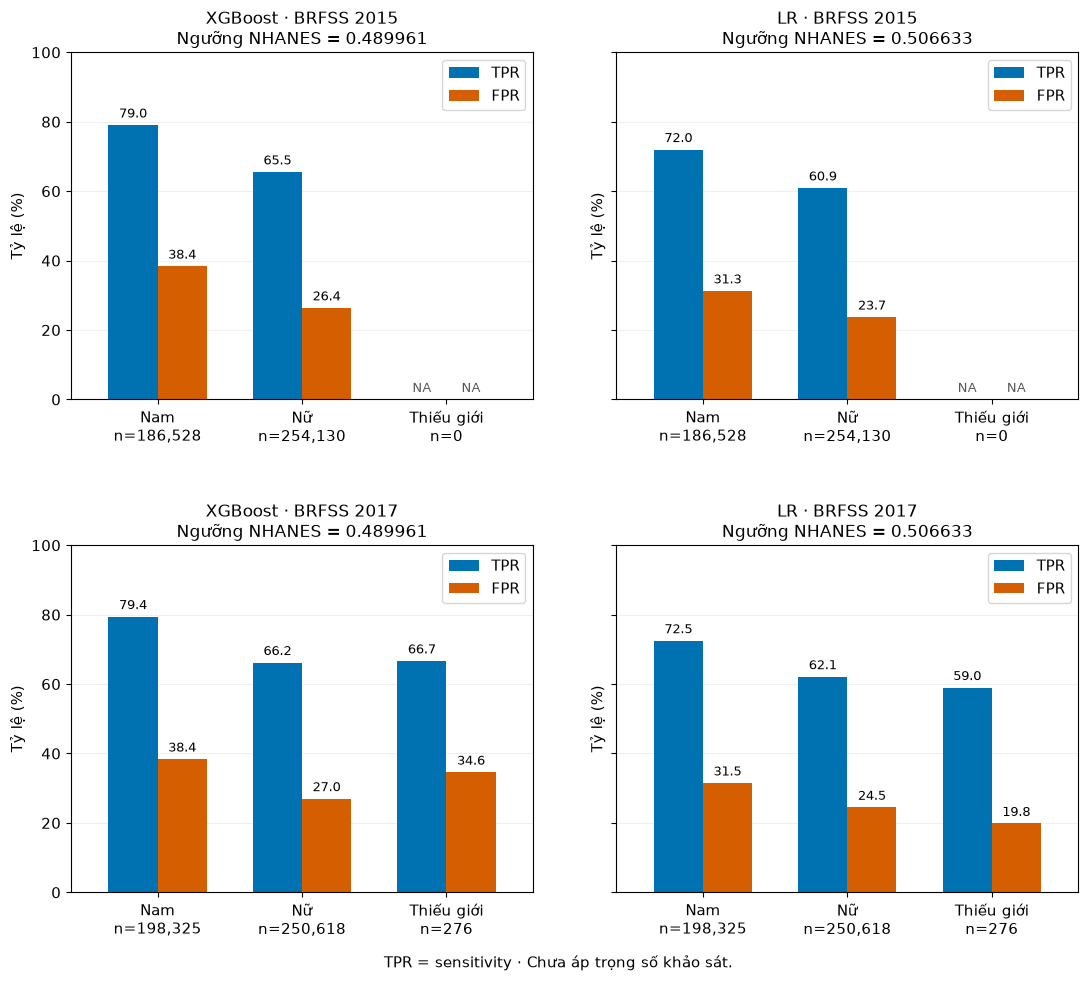

In [4]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.titlesize": 12, "axes.labelsize": 11})
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharey=True)
group_order = ["Nam", "Nữ", "Thiếu giới"]
positions = np.arange(3)
width = 0.34
for i, year in enumerate([2015, 2017]):
    for j, model in enumerate(["XGBoost", "LR"]):
        ax = axes[i, j]
        groups = group_metrics.query("year == @year and model == @model").set_index("sex_group").loc[group_order]
        for metric, label, offset, color in [
            ("tpr", "TPR", -width / 2, "#0072B2"),
            ("fpr", "FPR", width / 2, "#D55E00"),
        ]:
            values = groups[metric].to_numpy(dtype=float) * 100
            ax.bar(positions + offset, values, width, label=label, color=color)
            for x, value in zip(positions + offset, values):
                if np.isfinite(value):
                    ax.text(x, value + 1.3, f"{value:.1f}", ha="center", va="bottom", fontsize=9)
                else:
                    ax.text(x, 1.3, "NA", ha="center", va="bottom", fontsize=9, color="#555555")
        ax.set(xticks=positions,
               xticklabels=[f"{group}\nn={int(groups.loc[group, 'n']):,}" for group in group_order],
               title=f"{model} · BRFSS {year}\nNgưỡng NHANES = {thresholds[model]['youden']:.6f}",
               xlim=(-0.6, 2.6), ylim=(0, 100), ylabel="Tỷ lệ (%)")
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper right")
fig.subplots_adjust(bottom=0.10, top=0.94, hspace=0.42, wspace=0.18)
fig.text(0.5, 0.025, "TPR = sensitivity · Chưa áp trọng số khảo sát.", ha="center")
figure_paths = []
figure_paths.append(save_png(fig, figures_dir / "sex_tpr_fpr.png"))
plt.show()
plt.close(fig)


## Nhận xét

Nam có TPR/FPR và tỷ lệ dự đoán dương cao hơn, còn PPV thấp hơn Nữ ở cả hai mô hình và hai năm. Các chênh lệch mô tả chưa có CI/kiểm định, không đủ kết luận nguyên nhân hay phân biệt đối xử.

In [5]:
for filename, digest in frozen_hashes.items():
    assert hashlib.sha256(Path(filename).read_bytes()).hexdigest() == digest
pd.testing.assert_frame_equal(
    pd.read_csv(results_dir / "sex_group_metrics.csv"), group_metrics,
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-15,
)
pd.testing.assert_frame_equal(
    pd.read_csv(results_dir / "sex_gaps_pp.csv"), sex_gaps,
    check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-15,
)
manifest = {
    "final_run_id": final_run_id, "source": "saved external BRFSS predictions",
    "models": {"XGBoost": "primary", "LR": "reference"},
    "groups": {"1": "Nam", "2": "Nữ", "missing": "Thiếu giới"},
    "thresholds": {model: item["youden"] for model, item in thresholds.items()},
    "prediction_rule": "probability >= fixed NHANES Youden threshold, shared across sexes and years",
    "gap_direction": "male - female", "gap_unit": "percentage points",
    "equalized_odds_gap": "max(abs(TPR gap), abs(FPR gap)); NA if either component is NA",
    "undefined_metrics": "NA for zero denominator; AUC requires both classes; AP requires positives; empty group metrics NA",
    "survey_weighted": False, "confidence_intervals": False, "statistical_tests": False,
    "source_sha256": frozen_hashes,
}
output_files = [results_dir / name for name in ["sex_counts.csv", "sex_group_metrics.csv", "sex_gaps_pp.csv"]] + figure_paths
manifest["output_sha256"] = {str(p): hashlib.sha256(p.read_bytes()).hexdigest() for p in output_files}
(results_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame({"File": [str(p) for p in output_files]}))


,File
0,D:\NCKH Mini\diabetes-project\results\fairness...
1,D:\NCKH Mini\diabetes-project\results\fairness...
2,D:\NCKH Mini\diabetes-project\results\fairness...
3,D:\NCKH Mini\diabetes-project\results\figures\...
4,D:\NCKH Mini\diabetes-project\results\figures\...
